# Scraping Berita Saham - CNBC Indonesia (REVISI)
## 7 Emiten LQ45 Sektor Energi | Periode: Januari 2022 - Juni 2026

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45) - XGBoost & LSTM
**Penulis**: Ilda Nurida (NRP 6032251068) | **Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Tentang CNBC Indonesia
CNBC Indonesia (`cnbcindonesia.com`) adalah portal berita ekonomi dan bisnis
premium Indonesia (anak perusahaan Trans Media) dengan karakteristik:
- Fokus pada **pasar modal, analisis saham, rekomendasi analis, laporan keuangan**
- **Tag per emiten** dikurasi redaksi: `/tag/saham-{kode}`
- **Tidak ada paywall** — seluruh artikel dapat diakses penuh
- URL artikel mengandung **timestamp YYYYMMDDHHMMSS** → tanggal bisa langsung diambil dari URL

### Strategi Scraping (Dua Jalur)

**Jalur 1 — Tag per emiten** (presisi tinggi, artikel sudah dikurasi):
```
https://www.cnbcindonesia.com/tag/saham-{kode}
```
Halaman tag menggunakan **infinite scroll** — tidak ada parameter `?page=n`.
Solusi: ekstrak semua link `/market/`, `/research/`, `/mymoney/` yang muncul
di halaman tag (biasanya 20-30 artikel terbaru).

**Jalur 2 — Pencarian keyword** (jangkauan lebih luas, periode lebih panjang):
```
https://www.cnbcindonesia.com/search/?query={keyword}&p={n}
```
Paginasi dengan `?p=1, 2, 3, ...`

Kombinasi keduanya memaksimalkan jumlah artikel yang terkumpul.

### Keistimewaan Tanggal CNBC Indonesia
URL artikel mengandung timestamp lengkap, contoh:
```
/market/20260329195746-17-722290/saham-batu-bara-diborong-asing
         ^^^^^^^^^^^^^^^^
         YYYYMMDDHHMMSS  (bisa diambil langsung dari URL tanpa buka halaman)
```
Ini membuat CNBC Indonesia **paling efisien** — tanggal diketahui dari URL,
sehingga artikel di luar periode bisa langsung dilewati tanpa request ke server.

### Filter (4 lapis)

| Lapis | Target | Fungsi |
|---|---|---|
| F1 | URL | Buang non-artikel (foto, video, infografis, market-data, TV) |
| F2 | Headline | Buang judul tidak relevan |
| F3 | Headline + Isi | Wajib ada konteks saham/keuangan |
| F4 | Headline + Isi | Wajib kode/nama emiten disebut |

### Output
`berita_cnbc_lq45_energi.csv` — kolom standar:
`Sumber, Kode_Emiten, Keyword, Headline, Tanggal, Link, Isi_Berita`



### Ringkasan perbaikan

| # | Masalah lama | Perbaikan |
|---|---|---|
| 1 | Jalur 2 (search) **nol hasil** di semua keyword (hasil search dirender JS) | Probe menguji endpoint search; bila nihil, andalkan **Jalur 1 (tag) ber-pagination** |
| 2 | Headline kotor: "...SeginiMarket1 tahun yang lalu", prefix "FUNDAMENTAL PUNDIT..." | `clean_headline()` membersihkan sufiks kategori+waktu & prefix seksi |
| 3 | Jalur 1 hanya ambil **halaman-1** tiap tag | Pagination tag + berhenti adaptif |
| 4 | F4 kolaps (PGAS=0) karena selector body stale | **Auto-deteksi selector body** + fallback |
| 5 | Beberapa slug tag nihil | Multi-slug dipertahankan; yang nihil dilewati otomatis |

**Dipertahankan (sudah bagus)**: tanggal diambil langsung dari timestamp URL; F1-F4 lengkap dengan gate emiten.

> **PENTING**: jalankan **Bagian 6 (Probe)** sebelum Bagian 8.

## 1. Install Library

In [2]:
!pip install -q tqdm requests beautifulsoup4 lxml pandas
print("Library berhasil diinstall")

Library berhasil diinstall



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Library & Konfigurasi

In [3]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup as bs
from datetime import datetime, timedelta, timezone
import time, random, re
import pandas as pd
from pathlib import Path
from tqdm import tqdm

WIB = timezone(timedelta(hours=7))
start_date = datetime(2022, 1, 1, tzinfo=WIB)
end_date   = datetime(2026, 6, 30, 23, 59, 59, tzinfo=WIB)  # FIX: disamakan
# dengan Detik/Antara/Bloomberg/Kontan (sebelumnya 19 Juni -> cakupan timpang)

OUTPUT_DIR           = Path('../../03_dataset/raw')
OUTPUT_DIR_DASHBOARD = Path('../../dashboard/data')
CHECKPOINT_DIR       = Path('checkpoint_cnbc')
for d in (OUTPUT_DIR, OUTPUT_DIR_DASHBOARD, CHECKPOINT_DIR):
    d.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / 'berita_cnbc_lq45_energi.csv'
BASE_URL    = 'https://www.cnbcindonesia.com'

print("Konfigurasi siap")
print(f"Periode : {start_date:%d %B %Y} s/d {end_date:%d %B %Y}")
print(f"Output  : {OUTPUT_FILE}")

Konfigurasi siap
Periode : 01 January 2022 s/d 30 June 2026
Output  : ..\..\03_dataset\raw\berita_cnbc_lq45_energi.csv


## 3. Daftar 7 Emiten, Tag, Keyword, & Alias

In [4]:
EMITEN_TAG = {
    'ADRO': ['saham-adro', 'adro', 'adaro-energy', 'alamtri-resources', 'adaro'],
    'ADMR': ['saham-admr', 'adaro-minerals'],
    'ITMG': ['saham-itmg', 'indo-tambangraya', 'itmg'],
    'PTBA': ['saham-ptba', 'bukit-asam', 'ptba'],
    'MEDC': ['saham-medc', 'medco-energi', 'medco'],
    'AKRA': ['saham-akra', 'akr-corporindo', 'akra'],
    'PGAS': ['saham-pgas', 'perusahaan-gas-negara', 'pgn', 'pgas'],
}
EMITEN_KW = {
    'ADRO': ['Adaro', 'Alamtri', 'ADRO'],
    'ADMR': ['Adaro Minerals', 'ADMR'],
    'ITMG': ['Indo Tambangraya', 'ITMG'],
    'PTBA': ['Bukit Asam', 'PTBA'],
    'MEDC': ['Medco', 'MEDC'],
    'AKRA': ['AKR Corporindo', 'AKRA'],
    'PGAS': ['PGN', 'Perusahaan Gas Negara', 'PGAS'],
}
EMITEN_ALIAS = {
    'ADRO': ['adro', 'adaro energy', 'adaro', 'alamtri'],
    'ADMR': ['admr', 'adaro minerals'],
    'ITMG': ['itmg', 'indo tambangraya', 'tambangraya', 'itm'],
    'PTBA': ['ptba', 'bukit asam'],
    'MEDC': ['medc', 'medco'],
    'AKRA': ['akra', 'akr corporindo', 'akr'],
    'PGAS': ['pgas', 'perusahaan gas negara', 'pgn'],
}
NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk (Alamtri Resources Indonesia Tbk)',
    'ADMR': 'Adaro Minerals Indonesia Tbk', 'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk', 'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk', 'PGAS': 'Perusahaan Gas Negara Tbk',
}
URUTAN_EMITEN = list(EMITEN_TAG.keys())
print(f"Total emiten: {len(EMITEN_TAG)}")
for k in URUTAN_EMITEN:
    print(f"  {k}: {len(EMITEN_TAG[k])} tag | {len(EMITEN_KW[k])} keyword")

Total emiten: 7
  ADRO: 5 tag | 3 keyword
  ADMR: 2 tag | 2 keyword
  ITMG: 3 tag | 2 keyword
  PTBA: 3 tag | 2 keyword
  MEDC: 3 tag | 2 keyword
  AKRA: 3 tag | 2 keyword
  PGAS: 4 tag | 3 keyword


## 4. Filter (F1-F4) & Pembersih Headline

In [5]:
# ══════════════════════════════════════════════════════════════════════════
# FIX AUDIT — PENCOCOKAN ALIAS DENGAN BATAS KATA (WORD BOUNDARY)
# ══════════════════════════════════════════════════════════════════════════
# Versi lama memakai substring polos (`alias in teks`) sehingga alias pendek
# ikut cocok di dalam kata lain: 'pgn' cocok pada "pgnXYZ", 'itm' pada
# "itmxyz", 'akr' pada "akronim". Akibatnya banyak berita BUMN/Pertamina
# umum ikut tersimpan sebagai PGAS (false positive). Tiga fungsi di bawah
# menggantikannya dengan pencocokan KATA UTUH.
# ══════════════════════════════════════════════════════════════════════════
import re as _re

def _sebut(alias_list, teks):
    """True bila salah satu alias muncul sebagai KATA UTUH di `teks`."""
    for a in alias_list:
        a = str(a).strip()
        if a and _re.search(rf'(?<!\w){_re.escape(a)}(?!\w)', teks):
            return True
    return False

def _hitung_sebut(alias_list, teks):
    """Jumlah kemunculan alias sebagai kata utuh (maksimum antar alias)."""
    return max((len(_re.findall(rf'(?<!\w){_re.escape(str(a).strip())}(?!\w)', teks))
                for a in alias_list if str(a).strip()), default=0)

def _posisi_sebut(alias_list, teks):
    """Posisi karakter kemunculan pertama alias sebagai kata utuh (1e9 bila nihil)."""
    kandidat = []
    for a in alias_list:
        a = str(a).strip()
        if not a:
            continue
        m = _re.search(rf'(?<!\w){_re.escape(a)}(?!\w)', teks)
        if m:
            kandidat.append(m.start())
    return min(kandidat) if kandidat else 10**9


TIPE_BUANG_URL = ['/foto/', '/video/', '/infografis/', '/tv/', '/live/',
                  '/market-data/', 'market-data/quote', '/lifestyle/', '/tech/gadget']
def filter_url(link):
    l = str(link).lower()
    if any(t in l for t in TIPE_BUANG_URL):
        return False
    return bool(re.search(r'/\d{14}-\d+-\d+/', l))

KATA_BUANG_HEADLINE = ['wisata', 'liburan', 'kuliner', 'resep', 'makanan', 'fashion',
    'skincare', 'film', 'artis', 'gosip', 'musik', 'konser', 'drakor', 'bola',
    'liga', 'pertandingan', 'horoskop', 'zodiak', 'tips kesehatan', 'penyakit', 'vaksin']
def filter_headline(headline):
    h = str(headline).lower()
    return not any(k in h for k in KATA_BUANG_HEADLINE)

KATEGORI_CNBC = ['Market', 'News', 'Research', 'MyMoney', 'Syariah', 'Entrepreneur',
                 'Tech', 'Lifestyle', 'Opini', 'Investment', 'Fintech']
PREFIX_SEKSI = ['FUNDAMENTAL PUNDIT', 'CNBC INDONESIA RESEARCH', 'CUAP-CUAP CUAN',
                'MARKET BUZZ', 'INVESTIME', 'CLOSING BELL']
_re_suffix = re.compile(
    r'(' + '|'.join(KATEGORI_CNBC) + r')\s*\d+\s+(menit|jam|hari|minggu|bulan|tahun)\s+yang\s+lalu\s*$',
    re.I)
_re_suffix2 = re.compile(r'(' + '|'.join(KATEGORI_CNBC) + r')\s*$')
def clean_headline(h):
    h = str(h).strip()
    h = _re_suffix.sub('', h)
    h = _re_suffix2.sub('', h)
    up = h.upper()
    for p in PREFIX_SEKSI:
        if up.startswith(p):
            h = h[len(p):]; break
    return re.sub(r'\s{2,}', ' ', h).strip(' -|,:')

KATA_KONTEKS_SAHAM = ['saham', 'bursa', 'bei', 'idx', 'ihsg', 'emiten', 'investor',
    'laba', 'rugi', 'pendapatan', 'revenue', 'kinerja', 'keuangan', 'kuartal',
    'dividen', 'buyback', 'merger', 'akuisisi', 'ipo', 'target harga', 'rekomendasi',
    'analis', 'sekuritas', 'valuasi', 'harga saham', 'koreksi', 'menguat', 'melemah',
    'melesat', 'net buy', 'net sell', 'laba bersih', 'net profit', 'produksi',
    'batubara', 'batu bara', 'minyak', 'gas', 'lifting', 'ekspor', 'rupst']
def lolos_relevansi(kode, headline, isi):
    teks = (str(headline) + ' ' + str(isi)).lower()
    alias = EMITEN_ALIAS.get(kode, [kode.lower()])
    if not _sebut(alias, teks):
        return False, 'tidak_sebut_emiten'
    n = sum(1 for k in KATA_KONTEKS_SAHAM if k in teks)
    if n >= 1 or _sebut(alias, str(headline).lower()):
        return True, f'ok({n})'
    return False, 'konteks_lemah'

print("Filter & clean_headline siap. Contoh:")
for s in ['Alamtri (ADRO) Umumkan Kurs Dividen, Investor Dapat SeginiMarket1 tahun yang lalu',
          'FUNDAMENTAL PUNDITCatat Laba Bombastis 175%, Waspada Investor',
          'Tuntaskan RUPSLB, PGN Resmi Ubah Nama & Penyesuaian Anggaran DasarNews5 bulan yang lalu']:
    print(f"  {s[:55]!r}...\n    -> {clean_headline(s)!r}")

Filter & clean_headline siap. Contoh:
  'Alamtri (ADRO) Umumkan Kurs Dividen, Investor Dapat Seg'...
    -> 'Alamtri (ADRO) Umumkan Kurs Dividen, Investor Dapat Segini'
  'FUNDAMENTAL PUNDITCatat Laba Bombastis 175%, Waspada In'...
    -> 'Catat Laba Bombastis 175%, Waspada Investor'
  'Tuntaskan RUPSLB, PGN Resmi Ubah Nama & Penyesuaian Ang'...
    -> 'Tuntaskan RUPSLB, PGN Resmi Ubah Nama & Penyesuaian Anggaran Dasar'


## 5. Session, Parser Tanggal (dari URL), Ekstraktor Body

In [6]:
USER_AGENTS = [
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/123.0.0.0 Safari/537.36',
    'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36',
    'Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:124.0) Gecko/20100101 Firefox/124.0',
]
def get_headers():
    return {'User-Agent': random.choice(USER_AGENTS),
            'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
            'Accept-Language': 'id-ID,id;q=0.9,en-US;q=0.8,en;q=0.7',
            'Referer': 'https://www.cnbcindonesia.com/'}
def buat_session():
    # FIX AUDIT: 429 SENGAJA TIDAK masuk status_forcelist. Bila 429 ditangani
    # urllib3 (backoff_factor=2) DAN loop manual safe_get() sekaligus, jedanya
    # berlipat -> run bisa macet berjam-jam. Rate-limit ditangani SEPENUHNYA
    # oleh safe_get() di bawah.
    s = requests.Session()
    retry = Retry(total=4, backoff_factor=2, status_forcelist=[500, 502, 503, 504])  # FIX AUDIT: 429 dihapus

    s.mount('https://', HTTPAdapter(max_retries=retry))
    return s
sess = buat_session()

def safe_get(url, timeout=25, max_retry=3):
    global sess
    for attempt in range(1, max_retry + 1):
        try:
            r = sess.get(url, headers=get_headers(), timeout=timeout)
            if r.status_code == 429:
                wait = 60 * attempt
                print(f"  Rate-limit 429 - tunggu {wait}s..."); time.sleep(wait)
                sess = buat_session(); continue
            return r
        except requests.exceptions.ConnectionError as e:
            print(f"  ConnectionError ({attempt}/{max_retry}): {str(e)[:60]}")
            time.sleep(10 * attempt); sess = buat_session()
        except requests.exceptions.Timeout:
            time.sleep(5 * attempt)
        except Exception as e:
            print(f"  Error: {e}"); return None
    return None

def parse_date_dari_url(url):
    m = re.search(r'/(\d{4})(\d{2})(\d{2})(\d{2})(\d{2})(\d{2})-', str(url))
    if m:
        y, mo, d, h, mn, s = m.groups()
        try:
            return datetime(int(y), int(mo), int(d), int(h), int(mn), int(s), tzinfo=WIB)
        except ValueError:
            pass
    return None

NOISE_CNBC = ['Baca juga:', 'BACA JUGA:', 'Baca Juga:', 'CNBC Indonesia Research',
              'Reporter:', 'Editor:', 'ADVERTISEMENT', 'Artikel Terkait',
              'Saksikan video di bawah ini:']
def clean_text(text):
    for n in NOISE_CNBC:
        text = text.replace(n, '')
    return re.sub(r'\s{2,}', ' ', text).strip()

BODY_SELECTORS = ['div.detail-text', 'div.detail_text', 'article.detail-wrapper',
                  'div.content-detail', 'div[class*="detail-text"]',
                  'div[itemprop="articleBody"]', 'article']
DETECTED_BODY_SEL = None
def content_cnbc(url):
    global DETECTED_BODY_SEL
    r = safe_get(url)
    if not r: return ''
    soup = bs(r.text, 'lxml')
    sels = ([DETECTED_BODY_SEL] if DETECTED_BODY_SEL else []) + BODY_SELECTORS
    for sel in sels:
        if not sel: continue
        el = soup.select_one(sel)
        if el:
            ps = el.find_all('p')
            txt = clean_text(' '.join(p.get_text(strip=True) for p in ps)) if ps \
                  else clean_text(el.get_text(' ', strip=True))
            if len(txt) > 300:
                return txt
    allp = [p.get_text(strip=True) for p in soup.find_all('p')]
    return clean_text(' '.join(p for p in allp if len(p) > 40))

print("Session, parser tanggal-dari-URL, ekstraktor body siap")

Session, parser tanggal-dari-URL, ekstraktor body siap


## 6. PROBE: Validasi Endpoint Search & Auto-deteksi Selector Body

In [7]:
import requests as _rq

def kumpul_links(soup, seen=None):
    seen = seen or set()
    out, seen_page = [], set()
    for a in soup.find_all('a', href=True):
        href = a['href']
        if not re.search(r'/\d{14}-\d+-\d+/', href): continue
        if not href.startswith('http'): href = BASE_URL + href
        if 'cnbcindonesia' not in href: continue
        title = clean_headline(a.get_text(strip=True))
        if len(title) < 8: continue
        if href in seen or href in seen_page: continue
        seen_page.add(href)
        out.append((href, title, parse_date_dari_url(href)))
    return out

SEARCH_VARIAN = [
    lambda kw, p: f'{BASE_URL}/search/?query={_rq.utils.quote(kw)}&p={p}',
    lambda kw, p: f'{BASE_URL}/search?query={_rq.utils.quote(kw)}&page={p}',
    lambda kw, p: f'{BASE_URL}/search/{_rq.utils.quote(kw)}/{p}',
]
SEARCH_BUILDER = None
SEARCH_AKTIF = False
def probe_search(kw='Adaro'):
    global SEARCH_BUILDER, SEARCH_AKTIF
    print("  Menguji endpoint search...")
    for i, b in enumerate(SEARCH_VARIAN):
        try:
            n = len(kumpul_links(bs(safe_get(b(kw, 1)).text, 'lxml')))
            print(f"    varian {i}: {b(kw,1)[:60]} -> {n} link")
            if n > 0:
                SEARCH_BUILDER, SEARCH_AKTIF = b, True
                print(f"  -> Search AKTIF (varian {i})"); return
        except Exception as e:
            print(f"    varian {i}: error {str(e)[:40]}")
    print("  -> Search TIDAK aktif (kemungkinan dirender JS). Andalkan Jalur 1 (tag).")

def probe_body(sample_url):
    global DETECTED_BODY_SEL
    soup = bs(safe_get(sample_url).text, 'lxml')
    print(f"  Uji selector body: {sample_url[:60]}")
    best, best_n = None, 0
    for sel in BODY_SELECTORS:
        el = soup.select_one(sel)
        n = len(el.get_text(strip=True)) if el else 0
        if n > best_n: best, best_n = sel, n
        print(f"    {sel:30}: {n:5d}{'  <-' if n > 400 else ''}")
    if best_n > 400:
        DETECTED_BODY_SEL = best
        print(f"  -> Body selector: '{best}' ({best_n} char)")
    else:
        print("  -> Fallback klaster <p>.")

probe_search('Adaro')

_ex = []
for slug in EMITEN_TAG['ADRO']:
    _ex = kumpul_links(bs(safe_get(f'{BASE_URL}/tag/{slug}').text, 'lxml'))
    if _ex: break
if _ex:
    probe_body(_ex[0][0])
else:
    print("Tidak ada artikel contoh dari tag ADRO untuk uji body.")

  Menguji endpoint search...
    varian 0: https://www.cnbcindonesia.com/search/?query=Adaro&p=1 -> 0 link
    varian 1: https://www.cnbcindonesia.com/search?query=Adaro&page=1 -> 0 link
    varian 2: https://www.cnbcindonesia.com/search/Adaro/1 -> 0 link
  -> Search TIDAK aktif (kemungkinan dirender JS). Andalkan Jalur 1 (tag).
  Uji selector body: https://www.cnbcindonesia.com/market/20260417132858-17-72763
    div.detail-text               :  1795  <-
    div.detail_text               :     0
    article.detail-wrapper        :     0
    div.content-detail            :     0
    div[class*="detail-text"]     :  1795  <-
    div[itemprop="articleBody"]   :     0
    article                       :  1972  <-
  -> Body selector: 'article' (1972 char)


## 7. Scraper Utama (Jalur 1 tag ber-pagination + Jalur 2 kondisional)

In [8]:
def _tag_page_url(slug, page):
    return f'{BASE_URL}/tag/{slug}' if page == 1 else f'{BASE_URL}/tag/{slug}?page={page}'

def scrape_cnbc(kode, max_pages_tag=15, max_pages_search=30, patience=2,
                d_min=1.5, d_max=3.0, checkpoint_dir=CHECKPOINT_DIR):
    checkpoint_file = checkpoint_dir / f'{kode}_checkpoint.csv'
    if checkpoint_file.exists():
        df_ckpt = pd.read_csv(checkpoint_file, encoding='utf-8-sig')
        results = df_ckpt.to_dict('records')
        seen    = set(df_ckpt['Link'].tolist())
        print(f'  Resume checkpoint: {len(results)} artikel')
    else:
        results, seen = [], set()

    stat = dict(kandidat=0, lolos_f1=0, lolos_f2=0, disimpan=0,
                out_of_range=0, body_kosong=0, ditolak=0, duplikat=0)

    def proses(link, title, dt, sumber_kw):
        if link in seen:
            stat['duplikat'] += 1; return
        stat['kandidat'] += 1; seen.add(link)
        if not filter_url(link):       return
        stat['lolos_f1'] += 1
        if not filter_headline(title): return
        stat['lolos_f2'] += 1
        if dt is None:                 return
        if not (start_date <= dt <= end_date):
            stat['out_of_range'] += 1; return
        time.sleep(random.uniform(d_min, d_max))
        body = content_cnbc(link)
        if not body.strip():
            stat['body_kosong'] += 1; return
        ok, _ = lolos_relevansi(kode, title, body)
        if not ok:
            stat['ditolak'] += 1; return
        results.append({'Sumber': 'CNBC Indonesia', 'Kode_Emiten': kode,
                        'Keyword': sumber_kw, 'Headline': title,
                        'Tanggal': dt.strftime('%Y-%m-%d %H:%M'),
                        'Link': link, 'Isi_Berita': body})
        stat['disimpan'] += 1
        tqdm.write(f'  [{stat["disimpan"]}] {title[:70]}')
        if stat['disimpan'] % 25 == 0:
            pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')

    print('  [JALUR 1] Tag per emiten (ber-pagination)')
    for slug in EMITEN_TAG[kode]:
        empty = 0
        for pg in range(1, max_pages_tag + 1):
            r = safe_get(_tag_page_url(slug, pg))
            if not r:
                empty += 1
                if empty >= patience: break
                continue
            kand = [(h, t, d) for h, t, d in kumpul_links(bs(r.text, 'lxml')) if h not in seen]
            if not kand:
                empty += 1
                if empty >= patience: break
                continue
            empty = 0
            if pg == 1:
                print(f'    tag/{slug}: hal {pg} -> {len(kand)} kandidat')
            for link, title, dt in tqdm(kand, desc=f'    tag/{slug} h{pg}', unit='art', leave=False):
                proses(link, title, dt, f'tag/{slug}')
            time.sleep(random.uniform(d_min, d_max))

    if SEARCH_AKTIF and SEARCH_BUILDER:
        print('  [JALUR 2] Pencarian keyword')
        for kw in EMITEN_KW[kode]:
            empty = 0
            for pg in range(1, max_pages_search + 1):
                r = safe_get(SEARCH_BUILDER(kw, pg))
                if not r:
                    empty += 1
                    if empty >= patience: break
                    continue
                kand = [(h, t, d) for h, t, d in kumpul_links(bs(r.text, 'lxml')) if h not in seen]
                if not kand:
                    empty += 1
                    if empty >= patience: break
                    continue
                empty = 0
                for link, title, dt in tqdm(kand, desc=f'    kw "{kw}" h{pg}', unit='art', leave=False):
                    proses(link, title, dt, kw)
                if all(d is not None and d < start_date for _, _, d in kand):
                    break
                time.sleep(random.uniform(d_min, d_max))
    else:
        print('  [JALUR 2] dilewati (search tidak aktif)')

    if results:
        pd.DataFrame(results).to_csv(checkpoint_file, index=False, encoding='utf-8-sig')
    print(f'\n  STATISTIK [{kode}]  ' + '-'*28)
    for k, v in stat.items():
        print(f'    {k:16}: {v:>6,}')
    return results

print("scrape_cnbc() siap")

scrape_cnbc() siap


## 8. Jalankan Scraping Semua Emiten

In [9]:
assert 'SEARCH_AKTIF' in dir(), "Jalankan PROBE (Bagian 6) lebih dulu!"

semua_artikel = []
mulai = datetime.now(WIB)
for kode in EMITEN_TAG:
    print("\n" + "=" * 65)
    print(f"  {kode} | CNBC Indonesia | Mulai {datetime.now(WIB):%H:%M:%S}")
    print("=" * 65)
    hasil = scrape_cnbc(kode)
    semua_artikel.extend(hasil)
    df_tmp = pd.DataFrame(semua_artikel).drop_duplicates(subset=['Link', 'Kode_Emiten'])
    df_tmp.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
    print(f"  Auto-save: {len(df_tmp):,} artikel | {(datetime.now(WIB)-mulai).total_seconds()/60:.1f} mnt")
    time.sleep(random.uniform(8, 15))

df_final = pd.DataFrame(semua_artikel).drop_duplicates(subset=['Link', 'Kode_Emiten']).reset_index(drop=True)
df_final.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print("\n" + "=" * 65)
print(f"  SELESAI | {(datetime.now(WIB)-mulai).total_seconds()/60:.1f} menit | {len(df_final):,} artikel")
print("=" * 65)
if len(df_final):
    print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())


  ADRO | CNBC Indonesia | Mulai 07:17:27
  Resume checkpoint: 269 artikel
  [JALUR 1] Tag per emiten (ber-pagination)
    tag/saham-adro: hal 1 -> 2 kandidat


    tag/adro: hal 1 -> 1 kandidat


    tag/adaro: hal 1 -> 3 kandidat


  [JALUR 2] dilewati (search tidak aktif)

  STATISTIK [ADRO]  ----------------------------
    kandidat        :      9
    lolos_f1        :      9
    lolos_f2        :      9
    disimpan        :      0
    out_of_range    :      2
    body_kosong     :      0
    ditolak         :      7
    duplikat        :      0
  Auto-save: 269 artikel | 0.6 mnt

  ADMR | CNBC Indonesia | Mulai 07:18:17
  Resume checkpoint: 38 artikel
  [JALUR 1] Tag per emiten (ber-pagination)


  [JALUR 2] dilewati (search tidak aktif)

  STATISTIK [ADMR]  ----------------------------
    kandidat        :      3
    lolos_f1        :      3
    lolos_f2        :      3
    disimpan        :      0
    out_of_range    :      2
    body_kosong     :      0
    ditolak         :      1
    duplikat        :      0
  Auto-save: 307 artikel | 1.0 mnt

  ITMG | CNBC Indonesia | Mulai 07:18:41
  Resume checkpoint: 73 artikel
  [JALUR 1] Tag per emiten (ber-pagination)
    tag/saham-itmg: hal 1 -> 1 kandidat


    tag/indo-tambangraya: hal 1 -> 4 kandidat


... (17 outputs left out)

    tag/pgn h2:  50%|█████     | 1/2 [00:02<00:02,  2.77s/art]

  [6] PGN Jalankan Proyek Jaringan Gas Menggunakan CNG


    tag/pgas: hal 1 -> 3 kandidat


  [JALUR 2] dilewati (search tidak aktif)

  STATISTIK [PGAS]  ----------------------------
    kandidat        :     17
    lolos_f1        :     17
    lolos_f2        :     17
    disimpan        :      6
    out_of_range    :      8
    body_kosong     :      0
    ditolak         :      3
    duplikat        :      0
  Auto-save: 1,019 artikel | 3.4 mnt

  SELESAI | 3.6 menit | 1,019 artikel
Kode_Emiten
ADRO    269
ADMR     38
ITMG     73
PTBA    277
MEDC     96
AKRA     46
PGAS    220


## 9. Rekap & Validasi (kontaminasi + sebaran tahun)

In [10]:
if 'df_final' not in dir() or df_final is None or len(df_final) == 0:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
print(f"Total artikel  : {len(df_final):,}")
print(f"Rentang tanggal: {df_final['Tanggal'].min():%Y-%m-%d} s/d {df_final['Tanggal'].max():%Y-%m-%d}")
print("\nPer emiten:")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())
print("\nPer tahun x emiten:")
print(pd.crosstab(df_final['Tanggal'].dt.year, df_final['Kode_Emiten']).reindex(columns=URUTAN_EMITEN, fill_value=0).to_string())

def _cek(row):
    teks = (str(row['Headline']) + ' ' + str(row['Isi_Berita'])).lower()
    return any(a in teks for a in EMITEN_ALIAS.get(row['Kode_Emiten'], []))
n_bad = (~df_final.apply(_cek, axis=1)).sum()
print(f"\nValidasi sebutan emiten: {len(df_final)-n_bad}/{len(df_final)} valid",
      "(BERSIH)" if n_bad == 0 else f"-> {n_bad} perlu ditinjau")

Total artikel  : 1,019
Rentang tanggal: 2022-01-02 s/d 2026-06-29

Per emiten:
Kode_Emiten
ADRO    269
ADMR     38
ITMG     73
PTBA    277
MEDC     96
AKRA     46
PGAS    220

Per tahun x emiten:
Kode_Emiten  ADRO  ADMR  ITMG  PTBA  MEDC  AKRA  PGAS
Tanggal                                              
2022           73    19    16    68    31    13    13
2023           79    11    22    44    25    21    32
2024           67     7    10    61    10     5    23
2025           35     0    24    67    20     7   124
2026           15     1     1    37    10     0    28

Validasi sebutan emiten: 1019/1019 valid (BERSIH)


## 10. Rekap Tabel Jumlah Artikel per Emiten

In [11]:
rows = []
for kode in URUTAN_EMITEN:
    df_e = df_final[df_final['Kode_Emiten'] == kode]
    if len(df_e) == 0:
        rows.append({'Kode_Emiten': kode, 'Nama_Perusahaan': NAMA_PERUSAHAAN[kode],
                     'Sumber': 'CNBC Indonesia', 'Jumlah_Artikel': 0,
                     'Periode_Awal': '-', 'Periode_Akhir': '-', 'Rata_rata_per_Bulan': 0.0})
        continue
    bulan_unik = df_e['Tanggal'].dt.to_period('M').nunique()
    rows.append({'Kode_Emiten': kode, 'Nama_Perusahaan': NAMA_PERUSAHAAN[kode],
                 'Sumber': 'CNBC Indonesia', 'Jumlah_Artikel': len(df_e),
                 'Periode_Awal': df_e['Tanggal'].min().date(),
                 'Periode_Akhir': df_e['Tanggal'].max().date(),
                 'Rata_rata_per_Bulan': round(len(df_e) / max(bulan_unik, 1), 1)})

tabel_rekap = pd.DataFrame(rows)
total_row = pd.DataFrame([{
    'Kode_Emiten': 'TOTAL', 'Nama_Perusahaan': '-', 'Sumber': 'CNBC Indonesia',
    'Jumlah_Artikel': tabel_rekap['Jumlah_Artikel'].sum(),
    'Periode_Awal': df_final['Tanggal'].min().date(),
    'Periode_Akhir': df_final['Tanggal'].max().date(),
    'Rata_rata_per_Bulan': round(tabel_rekap['Rata_rata_per_Bulan'].sum(), 1),
}])
tabel_rekap_final = pd.concat([tabel_rekap, total_row], ignore_index=True)
path_rekap = OUTPUT_DIR_DASHBOARD / 'rekap_berita_cnbc.csv'
tabel_rekap_final.to_csv(path_rekap, index=False, encoding='utf-8-sig')

print("=" * 80)
print("  REKAP ARTIKEL - CNBC INDONESIA (7 EMITEN)")
print("=" * 80)
display(tabel_rekap_final)
print(f"Disimpan: {path_rekap}")

  REKAP ARTIKEL - CNBC INDONESIA (7 EMITEN)


,Kode_Emiten,Nama_Perusahaan,Sumber,Jumlah_Artikel,Periode_Awal,Periode_Akhir,Rata_rata_per_Bulan
0,ADRO,Adaro Energy Indonesia Tbk (Alamtri Resources ...,CNBC Indonesia,269,2022-01-02,2026-04-17,5.4
1,ADMR,Adaro Minerals Indonesia Tbk,CNBC Indonesia,38,2022-01-03,2026-01-14,2.1
2,ITMG,Indo Tambangraya Megah Tbk,CNBC Indonesia,73,2022-01-02,2026-04-17,2.2
3,PTBA,Bukit Asam Tbk,CNBC Indonesia,277,2022-01-05,2026-06-11,5.4
4,MEDC,Medco Energi Internasional Tbk,CNBC Indonesia,96,2022-01-20,2026-05-21,2.7
5,AKRA,AKR Corporindo Tbk,CNBC Indonesia,46,2022-01-06,2025-09-09,2.1
6,PGAS,Perusahaan Gas Negara Tbk,CNBC Indonesia,220,2022-03-10,2026-06-29,5.2
7,TOTAL,-,CNBC Indonesia,1019,2022-01-02,2026-06-29,25.1


Disimpan: ..\..\dashboard\data\rekap_berita_cnbc.csv


## 11. Grafik Tren Volume Berita per Bulan per Emiten

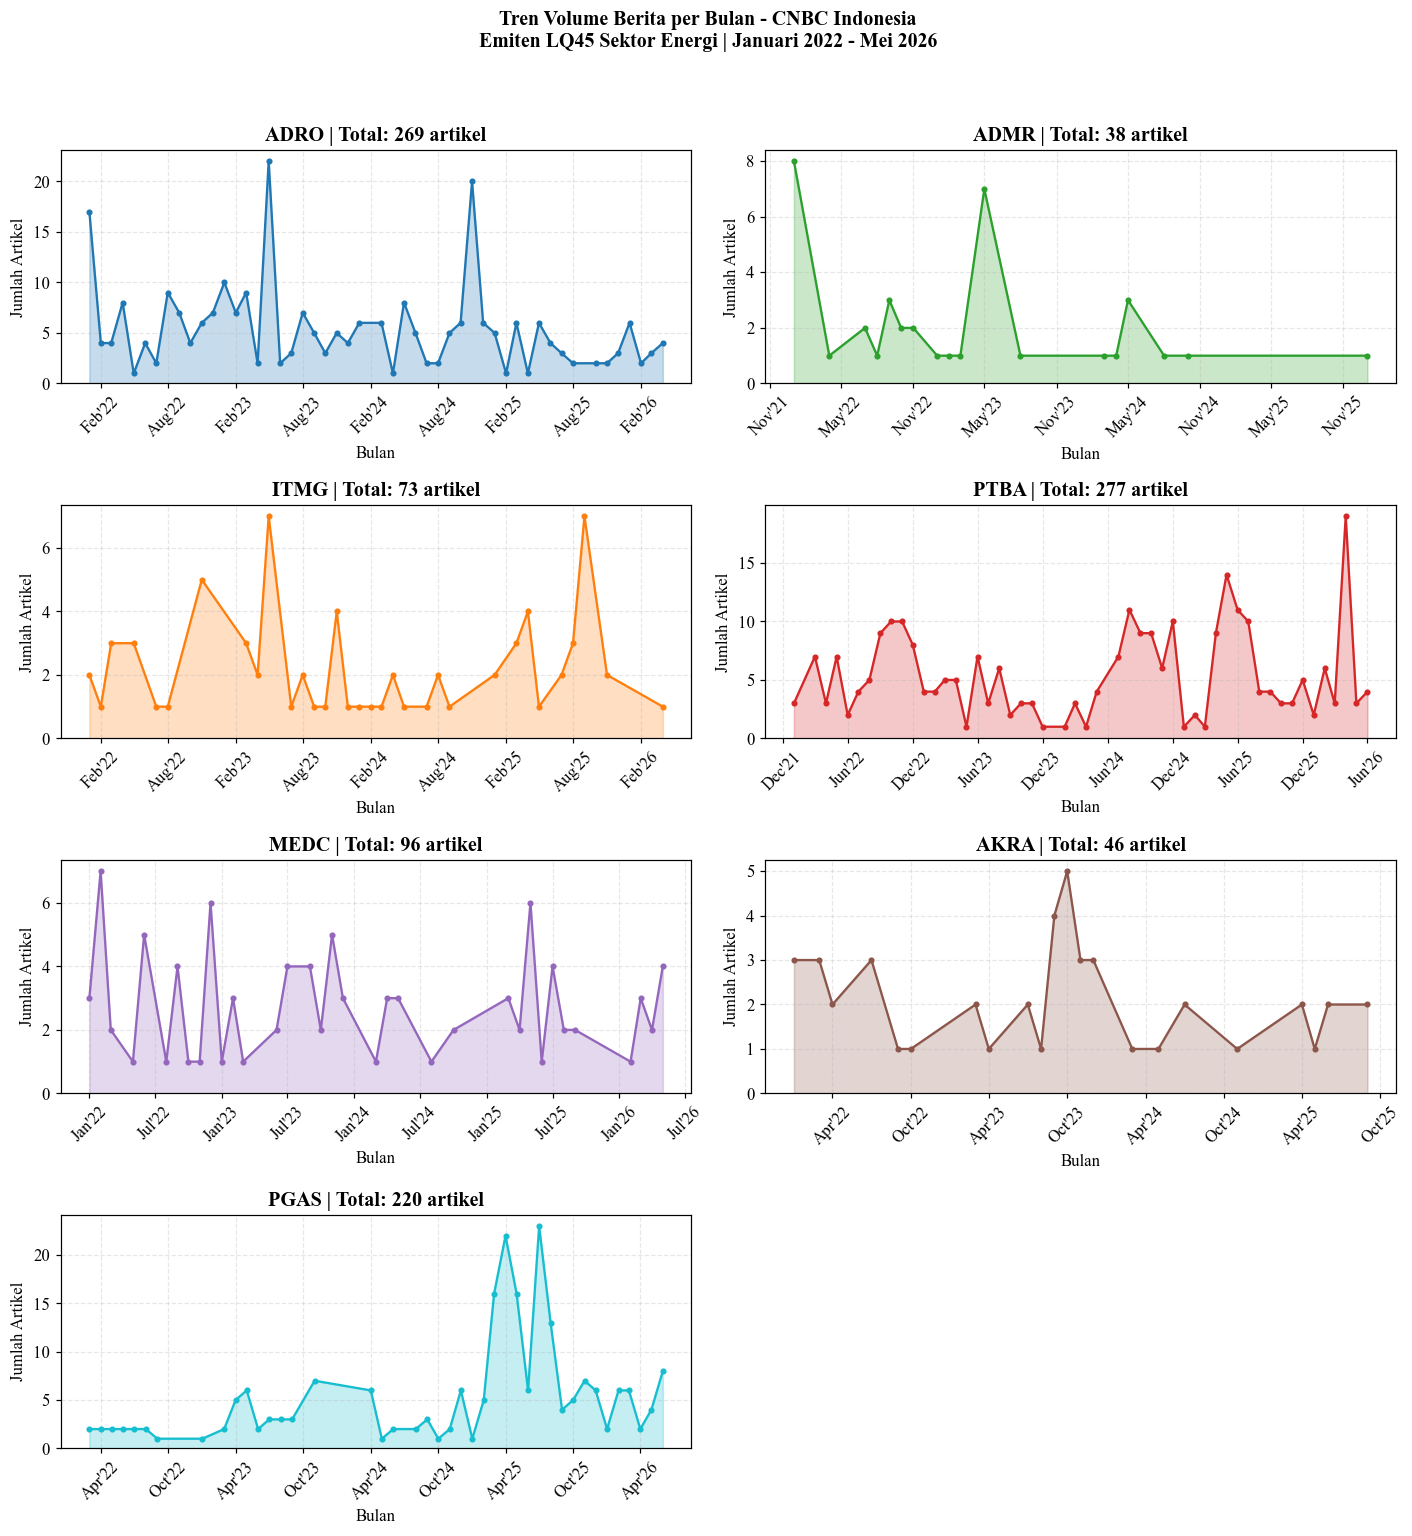

Gambar disimpan: ..\..\dashboard\data\tren_berita_cnbc_per_emiten.png


In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11, 'figure.dpi': 110})

WARNA = {'ADRO': '#1f77b4', 'ADMR': '#2ca02c', 'ITMG': '#ff7f0e',
          'PTBA': '#d62728', 'MEDC': '#9467bd', 'AKRA': '#8c564b', 'PGAS': '#17becf'}

df_final['Bulan_str'] = df_final['Tanggal'].dt.to_period('M').astype(str)
df_bul = df_final.groupby(['Bulan_str', 'Kode_Emiten']).size().reset_index(name='Jumlah')
df_bul['Bulan_dt'] = pd.to_datetime(df_bul['Bulan_str'])

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    d  = df_bul[df_bul['Kode_Emiten'] == kode].sort_values('Bulan_dt')
    if len(d) > 0:
        ax.fill_between(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], alpha=0.25)
        ax.plot(d['Bulan_dt'], d['Jumlah'], color=WARNA[kode], linewidth=1.5,
                marker='o', markersize=3)
    total = int(d['Jumlah'].sum()) if len(d) > 0 else 0
    ax.set_title(f"{kode} | Total: {total} artikel", fontweight='bold')
    ax.set_xlabel('Bulan'); ax.set_ylabel('Jumlah Artikel')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y"))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, linestyle='--'); ax.set_ylim(bottom=0)

axes[-1].axis('off')
fig.suptitle('Tren Volume Berita per Bulan - CNBC Indonesia\n'
             'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
             fontsize=13, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar = OUTPUT_DIR_DASHBOARD / 'tren_berita_cnbc_per_emiten.png'
fig.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()
print(f"Gambar disimpan: {path_gambar}")

## 12. Word Cloud Isi Berita per Emiten


[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Total artikel : 1,019
Kode_Emiten
ADRO    269
ADMR     38
ITMG     73
PTBA    277
MEDC     96
AKRA     46
PGAS    220


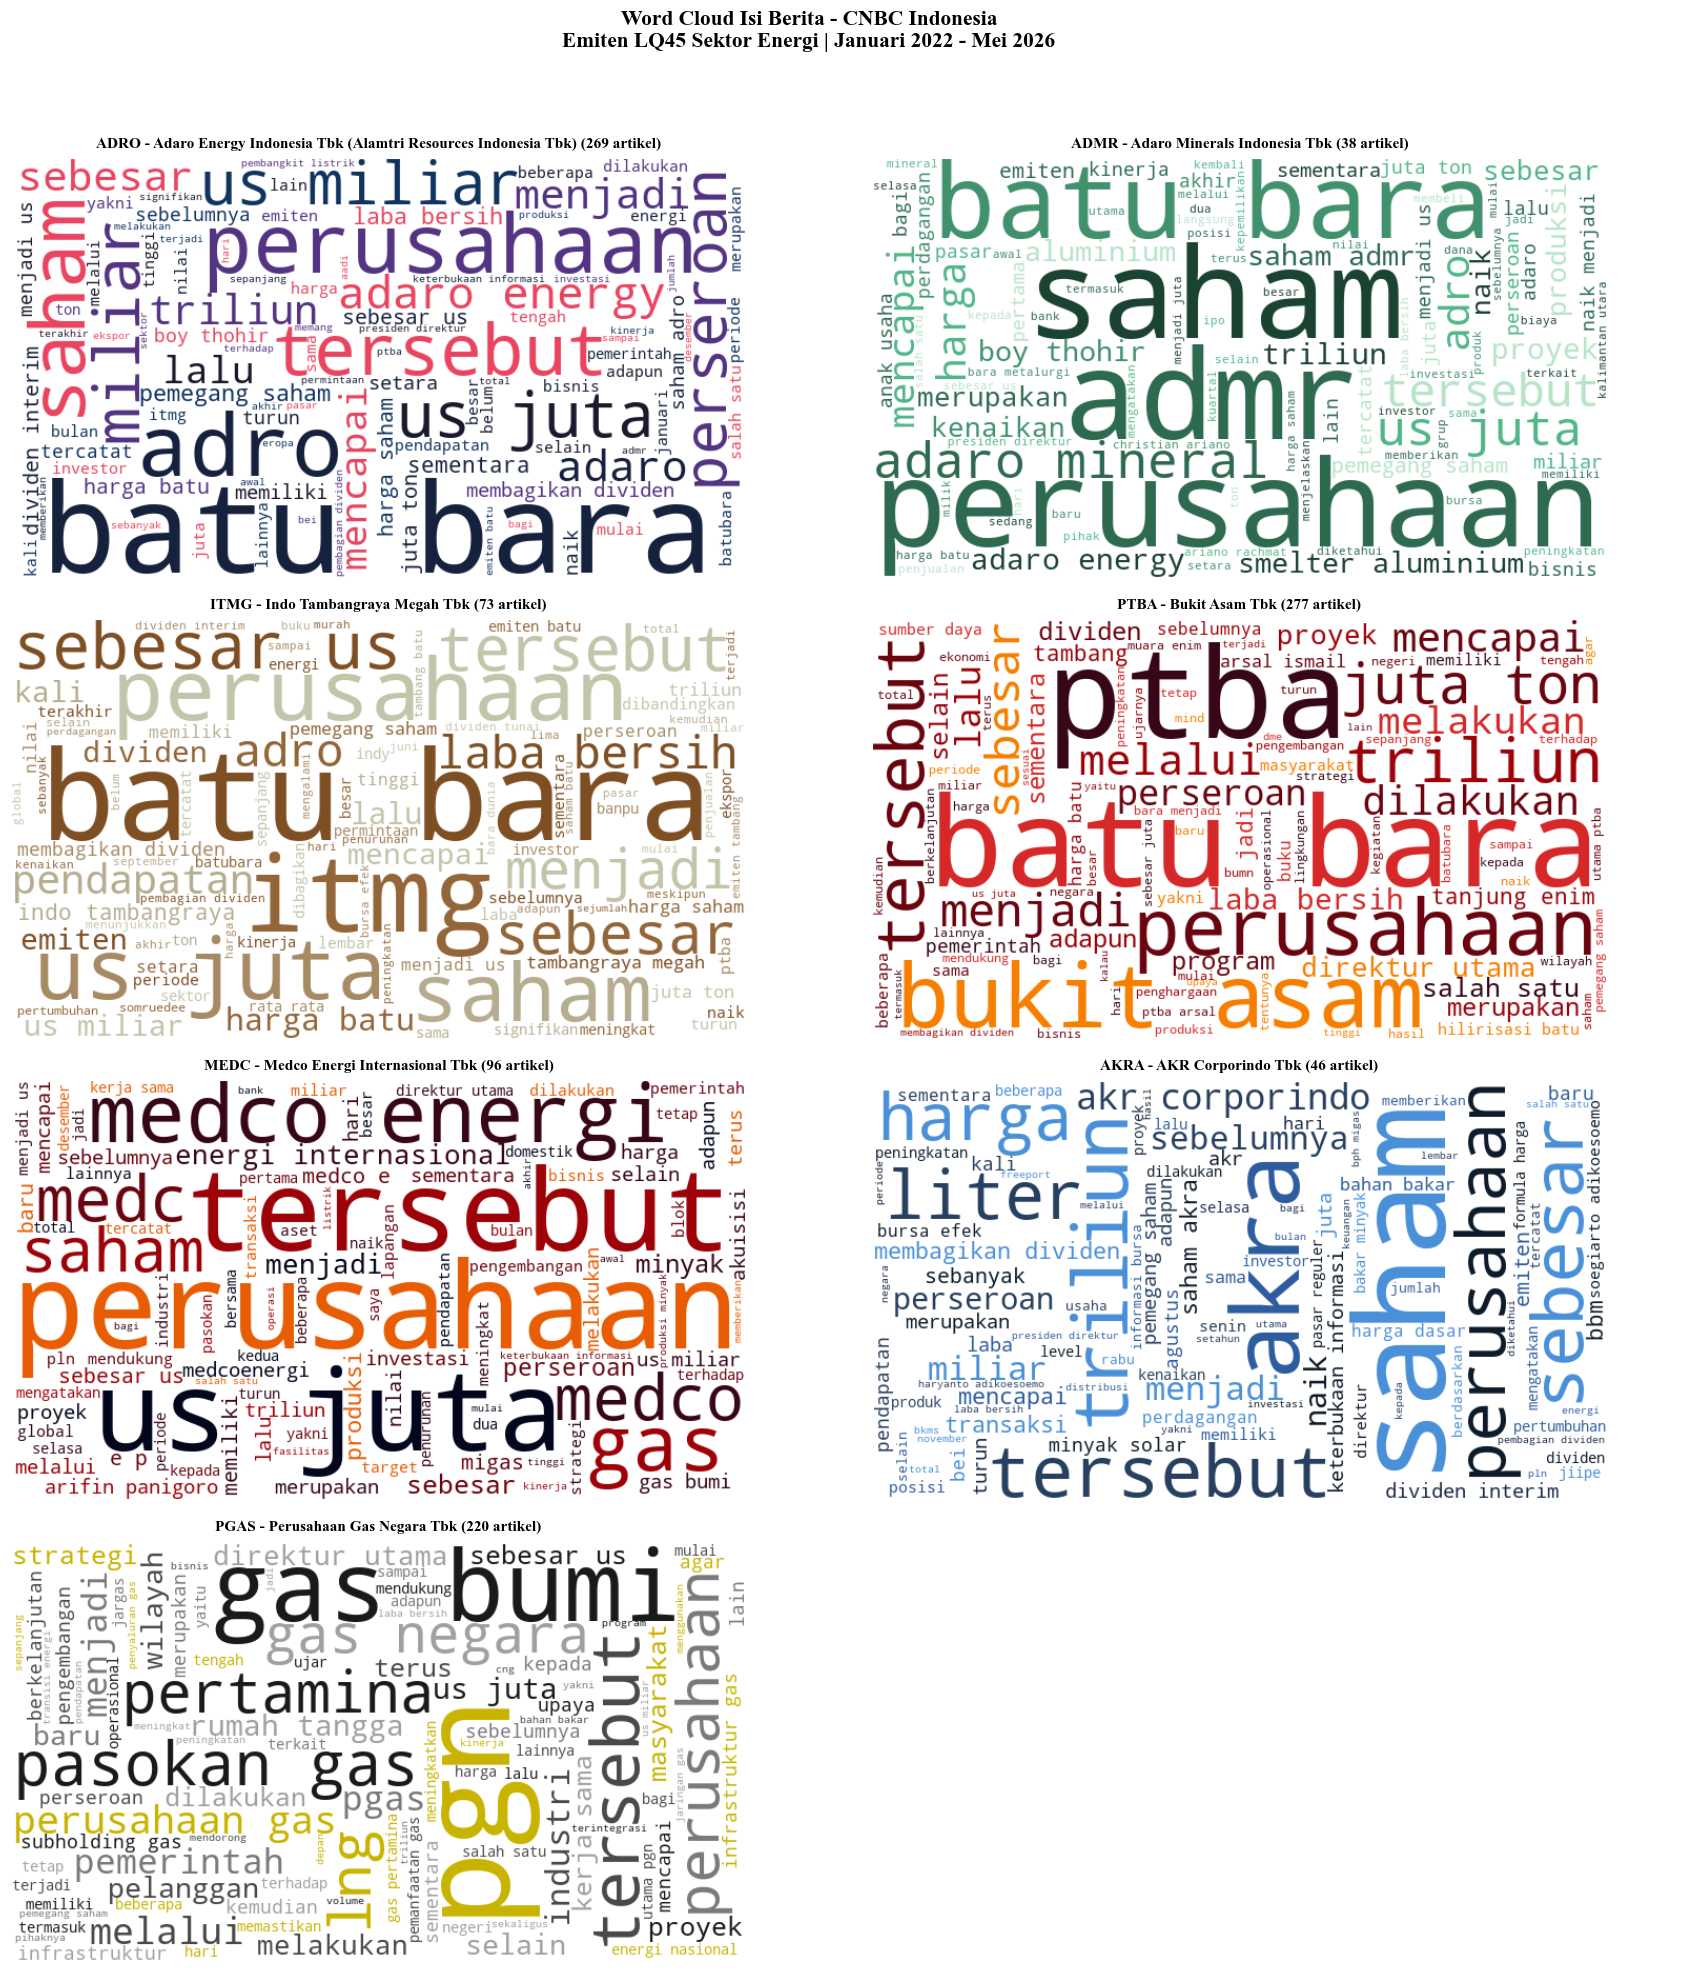

Word cloud disimpan: ..\..\dashboard\data\wordcloud_cnbc_per_emiten.png


In [13]:
!pip install wordcloud -q

from wordcloud import WordCloud

plt.rcParams.update({'font.family': 'Times New Roman', 'figure.dpi': 110})

PALET_WARNA = {
    'ADRO': ['#1a1a2e', '#16213e', '#0f3460', '#533483', '#e94560'],
    'ADMR': ['#1b4332', '#2d6a4f', '#40916c', '#52b788', '#b7e4c7'],
    'ITMG': ['#7f4f24', '#936639', '#a68a64', '#b6ad90', '#c2c5aa'],
    'PTBA': ['#370617', '#6a040f', '#9d0208', '#d62828', '#f77f00'],
    'MEDC': ['#03071e', '#370617', '#6a040f', '#9d0208', '#e85d04'],
    'AKRA': ['#0d1b2a', '#1b2a4a', '#274060', '#2e5d9f', '#4a90d9'],
    'PGAS': ['#1a1a1a', '#4a4a4a', '#7a7a7a', '#a0a0a0', '#c8b400'],
}

STOPWORDS_ID = {
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'dengan', 'untuk',
    'pada', 'adalah', 'dalam', 'tidak', 'juga', 'akan', 'sebagai', 'oleh',
    'atau', 'telah', 'sudah', 'dapat', 'bisa', 'ada', 'saat', 'tahun',
    'kata', 'serta', 'kami', 'kita', 'mereka', 'dia', 'ia', 'lebih',
    'namun', 'karena', 'sehingga', 'hal', 'jika', 'maka', 'antara',
    'baik', 'secara', 'seperti', 'ketika', 'setelah', 'sebelum', 'hingga',
    'sejak', 'selama', 'masih', 'hanya', 'sangat', 'pun',
    'tbk', 'pt', 'rp', 'persen', 'per', 'senilai', 'sekitar',
    'cnbc', 'indonesia', 'jakarta', 'co', 'id',
    'said', 'the', 'to', 'of', 'in', 'and', 'atas', 'bahwa',
    'baca', 'juga', 'reporter', 'editor',
}

if 'df_final' not in dir() or df_final is None:
    df_final = pd.read_csv(OUTPUT_FILE, encoding='utf-8-sig')
    print(f"Load dari file: {len(df_final)} artikel")

print(f"Total artikel : {len(df_final):,}")
print(df_final['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).to_string())

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()
MIN_ARTIKEL = 5

def make_color_func(palette):
    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        return palette[random_state.randint(0, len(palette) - 1)]
    return color_func

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_emiten = df_final[df_final['Kode_Emiten'] == kode]
    n_artikel  = len(df_emiten)
    nama_p     = globals().get('NAMA_PERUSAHAAN', {})

    if n_artikel < MIN_ARTIKEL:
        ax.text(0.5, 0.5, f'Data terlalu sedikit\n({n_artikel} artikel)',
                ha='center', va='center', transform=ax.transAxes, fontsize=11, color='gray')
        ax.set_title(f'{kode} - {nama_p.get(kode, kode)}', fontweight='bold', fontsize=10)
        ax.axis('off'); continue

    teks = ' '.join(df_emiten['Isi_Berita'].dropna().astype(str).str.lower().tolist())
    if not teks.strip():
        ax.text(0.5, 0.5, f'Isi berita kosong\n({kode})', ha='center', va='center',
                transform=ax.transAxes, fontsize=11)
        ax.set_title(f'{kode}', fontweight='bold'); ax.axis('off'); continue

    try:
        wc = WordCloud(width=700, height=400, background_color='white',
                       stopwords=STOPWORDS_ID, max_words=100, min_font_size=8,
                       max_font_size=120, collocations=True, prefer_horizontal=0.7,
                       relative_scaling=0.6,
                       color_func=make_color_func(PALET_WARNA[kode])).generate(teks)
        ax.imshow(wc, interpolation='bilinear')
        ax.set_title(f'{kode} - {nama_p.get(kode, kode)} ({n_artikel} artikel)',
                     fontweight='bold', fontsize=10, pad=8)
        ax.axis('off')
    except ValueError:
        ax.text(0.5, 0.5, f'Teks terlalu sedikit\nsetelah filtering\n({n_artikel} artikel)',
                ha='center', va='center', transform=ax.transAxes, fontsize=10, color='gray')
        ax.set_title(f'{kode}', fontweight='bold'); ax.axis('off')

axes[-1].axis('off')
fig.suptitle('Word Cloud Isi Berita - CNBC Indonesia\n'
             'Emiten LQ45 Sektor Energi | Januari 2022 - Mei 2026',
             fontsize=14, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])
path_wc = OUTPUT_DIR_DASHBOARD / 'wordcloud_cnbc_per_emiten.png'
fig.savefig(path_wc, dpi=200, bbox_inches='tight')
plt.show()
print(f"Word cloud disimpan: {path_wc}")

## 10. Simpan Output dengan Kolom Standar

In [14]:
KOLOM_STANDAR = ['Sumber', 'Kode_Emiten', 'Keyword', 'Headline', 'Tanggal', 'Link', 'Isi_Berita']
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'], errors='coerce')
for k in KOLOM_STANDAR:
    if k not in df_final.columns:
        df_final[k] = ''
df_save = df_final.copy()
df_save['Tanggal'] = df_save['Tanggal'].dt.strftime('%Y-%m-%d %H:%M')
df_save = df_save[KOLOM_STANDAR].drop_duplicates(subset=['Link', 'Kode_Emiten']).reset_index(drop=True)
df_save.to_csv(OUTPUT_FILE, index=False, encoding='utf-8-sig')
print(f"File disimpan : {OUTPUT_FILE}")
print(f"Total artikel : {len(df_save):,}")
print("LANGKAH SELANJUTNYA -> gabungkan dengan Detik, Kontan, Bisnis, ANTARA, Bloomberg")

File disimpan : ..\..\03_dataset\raw\berita_cnbc_lq45_energi.csv
Total artikel : 1,019
LANGKAH SELANJUTNYA -> gabungkan dengan Detik, Kontan, Bisnis, ANTARA, Bloomberg
